# Phase 1: Data Preprocessing & Normalization
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

Place the 8 CICIDS2017 `MachineLearningCSV` files in `data/raw/` before running.

## Step 0: Install & import libraries

In [ ]:
# Run once if needed:
# %pip install pandas numpy scikit-learn joblib matplotlib seaborn


In [1]:
import os, glob, re
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

RAW_DIR = "data/raw"
OUT_DIR = "data/processed"
RANDOM_STATE = 42
os.makedirs(OUT_DIR, exist_ok=True)
print("Setup done")

Setup done


## Step 1: Load and merge all CSV files

In [7]:
import os
import glob
import pandas as pd
from pathlib import Path

# Set project root
PROJECT_ROOT = Path.cwd().parent

# Set raw dataset directory
RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Find all CSV files
files = sorted(glob.glob(str(RAW_DIR / "*.csv")))

print("Raw dataset directory:", RAW_DIR.resolve())
print(f"Found {len(files)} CSV files")

# Check whether files exist
if not files:
    raise FileNotFoundError(
        f"No CSV files found in {RAW_DIR.resolve()}. "
        "Check your dataset folder location."
    )

# Read and merge CSV files
frames = []

for f in files:
    df_part = pd.read_csv(
        f,
        encoding="latin1",
        low_memory=False
    )

    # Remove leading/trailing spaces from column names
    df_part.columns = df_part.columns.str.strip()

    print(f"{os.path.basename(f):70s} {df_part.shape}")

    frames.append(df_part)

# Merge all datasets
df = pd.concat(frames, ignore_index=True)

# Release intermediate memory
del frames

print("\nMerged dataset shape:", df.shape)

# Display first five rows
display(df.head())

Raw dataset directory: C:\Users\arvin\Desktop\projects\adversarial-ids\data\raw
Found 8 CSV files
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                       (225745, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv                   (286467, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv                              (191033, 79)
Monday-WorkingHours.pcap_ISCX.csv                                      (529918, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv            (288602, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv                 (170366, 79)
Tuesday-WorkingHours.pcap_ISCX.csv                                     (445909, 79)
Wednesday-workingHours.pcap_ISCX.csv                                   (692703, 79)

Merged dataset shape: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## Step 2: Inspect the raw data

In [8]:
print(df.dtypes.value_counts())
print("\nMissing values:", df.isna().sum().sum())
num = df.select_dtypes(include=[np.number])
print("Inf values:", np.isinf(num).sum().sum())
print("Duplicate rows:", df.duplicated().sum())

int64      54
float64    24
str         1
Name: count, dtype: int64

Missing values: 1358
Inf values: 4376
Duplicate rows: 308381


## Step 3: Clean labels

In [9]:
# Web attack labels contain a broken character; normalise them
df["Label"] = df["Label"].astype(str).apply(lambda s: re.sub(r"[^\x00-\x7F]+", "-", s).strip())
df["Label"] = df["Label"].str.replace(r"\s*-\s*", " - ", regex=True)
print(df["Label"].value_counts())

Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP - Patator                    7938
SSH - Patator                    5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


## Step 4: Handle inf / NaN, duplicates, constant columns

In [10]:
n0 = len(df)
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
print(f"Removed {n0 - len(df):,} rows with inf/NaN")

n1 = len(df)
df.drop_duplicates(inplace=True)
print(f"Removed {n1 - len(df):,} duplicate rows")

feature_cols = [c for c in df.columns if c != "Label"]
const_cols = [c for c in feature_cols if df[c].nunique() <= 1]
df.drop(columns=const_cols, inplace=True)
print(f"Removed {len(const_cols)} constant columns: {const_cols}")

df.reset_index(drop=True, inplace=True)
print("Clean shape:", df.shape)

Removed 2,867 rows with inf/NaN
Removed 307,078 duplicate rows
Removed 8 constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Clean shape: (2520798, 71)


## Step 5: Encode labels (binary + multiclass)

In [11]:
y_binary = (df["Label"] != "BENIGN").astype(np.int8).values   # 0 = benign, 1 = attack

le = LabelEncoder()
y_multi = le.fit_transform(df["Label"]).astype(np.int8)
joblib.dump(le, os.path.join(OUT_DIR, "label_encoder.joblib"))

X = df.drop(columns=["Label"]).astype(np.float32)
feature_names = list(X.columns)
joblib.dump(feature_names, os.path.join(OUT_DIR, "feature_names.joblib"))

print("Features:", X.shape[1])
print("Benign:", (y_binary == 0).sum(), "| Attack:", (y_binary == 1).sum())
print(dict(zip(le.classes_, range(len(le.classes_)))))

Features: 70
Benign: 2095057 | Attack: 425741
{'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS GoldenEye': 3, 'DoS Hulk': 4, 'DoS Slowhttptest': 5, 'DoS slowloris': 6, 'FTP - Patator': 7, 'Heartbleed': 8, 'Infiltration': 9, 'PortScan': 10, 'SSH - Patator': 11, 'Web Attack - Brute Force': 12, 'Web Attack - Sql Injection': 13, 'Web Attack - XSS': 14}


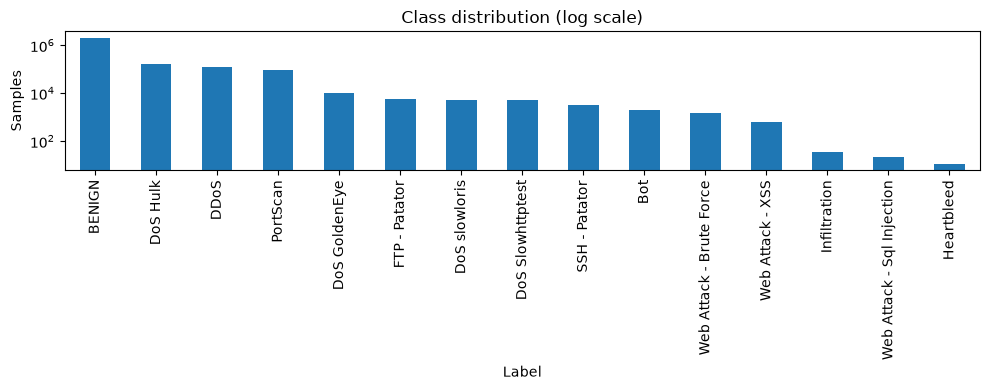

In [12]:
# Class distribution plot
counts = df["Label"].value_counts()
plt.figure(figsize=(10, 4))
counts.plot(kind="bar", logy=True)
plt.title("Class distribution (log scale)")
plt.ylabel("Samples")
plt.tight_layout()
plt.show()

## Step 6: Train / validation / test split (70 / 15 / 15, stratified)

In [13]:
idx = np.arange(len(X))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y_multi, random_state=RANDOM_STATE)
try:
    idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y_multi[idx_temp], random_state=RANDOM_STATE)
except ValueError:   # a very rare class has too few samples to stratify twice
    idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y_binary[idx_temp], random_state=RANDOM_STATE)

X_arr = X.values
X_train_raw, X_val_raw, X_test_raw = X_arr[idx_train], X_arr[idx_val], X_arr[idx_test]
y_train_bin, y_val_bin, y_test_bin = y_binary[idx_train], y_binary[idx_val], y_binary[idx_test]
y_train_multi, y_val_multi, y_test_multi = y_multi[idx_train], y_multi[idx_val], y_multi[idx_test]

for n, a, b in [("train", X_train_raw, y_train_bin), ("val", X_val_raw, y_val_bin), ("test", X_test_raw, y_test_bin)]:
    print(f"{n:5s} X={a.shape}  attack ratio={b.mean():.3f}")

train X=(1764558, 70)  attack ratio=0.169
val   X=(378120, 70)  attack ratio=0.169
test  X=(378120, 70)  attack ratio=0.169


## Step 7: Normalize with MinMaxScaler (fit on TRAIN only → no data leakage)
Scaling to [0, 1] makes the perturbation size ε in FGSM/PGD (Phase 3) mean the same thing for every feature.

In [14]:
scaler = MinMaxScaler(feature_range=(0, 1))
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val   = np.clip(scaler.transform(X_val_raw),  0, 1).astype(np.float32)
X_test  = np.clip(scaler.transform(X_test_raw), 0, 1).astype(np.float32)

joblib.dump(scaler, os.path.join(OUT_DIR, "minmax_scaler.joblib"))

print("Train min/max:", X_train.min(), X_train.max())
print("Val   min/max:", X_val.min(), X_val.max())
print("Test  min/max:", X_test.min(), X_test.max())
print("NaNs after scaling:", np.isnan(X_train).sum() + np.isnan(X_val).sum() + np.isnan(X_test).sum())

Train min/max: 0.0 1.0
Val   min/max: 0.0 1.0
Test  min/max: 0.0 1.0
NaNs after scaling: 0


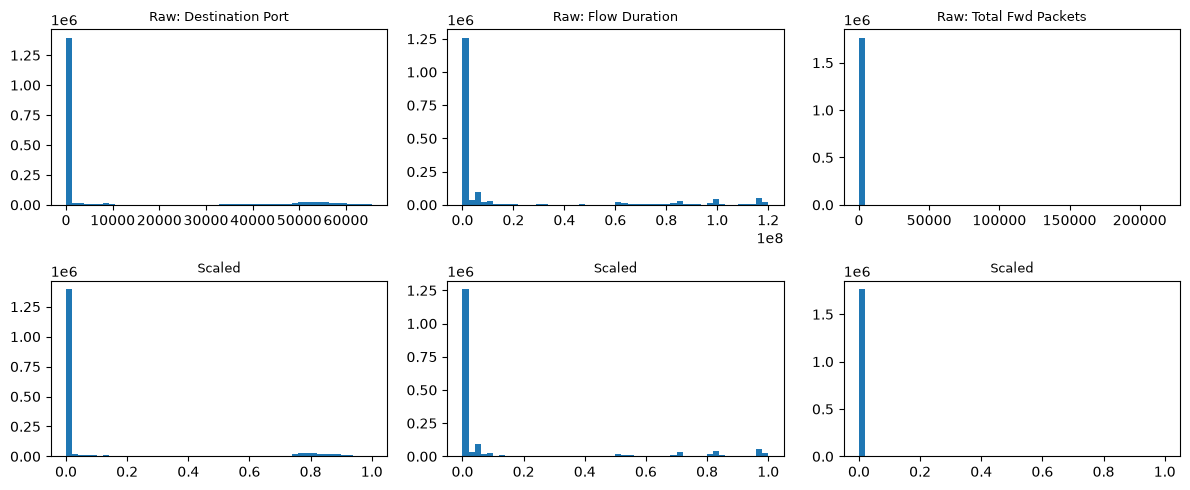

In [15]:
# Before vs after scaling for a few features
cols = [0, 1, 2]
fig, ax = plt.subplots(2, 3, figsize=(12, 5))
for j, c in enumerate(cols):
    ax[0, j].hist(X_train_raw[:, c], bins=50); ax[0, j].set_title(f"Raw: {feature_names[c]}", fontsize=9)
    ax[1, j].hist(X_train[:, c], bins=50);     ax[1, j].set_title("Scaled", fontsize=9)
plt.tight_layout(); plt.show()

## Step 8: Save processed data

In [17]:
np.save(f"{OUT_DIR}/X_train.npy", X_train); np.save(f"{OUT_DIR}/X_val.npy", X_val); np.save(f"{OUT_DIR}/X_test.npy", X_test)
np.save(f"{OUT_DIR}/y_train_binary.npy", y_train_bin); np.save(f"{OUT_DIR}/y_val_binary.npy", y_val_bin); np.save(f"{OUT_DIR}/y_test_binary.npy", y_test_bin)
np.save(f"{OUT_DIR}/y_train_multi.npy", y_train_multi); np.save(f"{OUT_DIR}/y_val_multi.npy", y_val_multi); np.save(f"{OUT_DIR}/y_test_multi.npy", y_test_multi)
print(sorted(os.listdir(OUT_DIR)))
print("Phase 1 complete")

['X_test.npy', 'X_train.npy', 'X_train_bal.npy', 'X_val.npy', 'feature_names.joblib', 'label_encoder.joblib', 'minmax_scaler.joblib', 'y_test_binary.npy', 'y_test_multi.npy', 'y_train_bal_binary.npy', 'y_train_bal_multi.npy', 'y_train_binary.npy', 'y_train_multi.npy', 'y_val_binary.npy', 'y_val_multi.npy']
Phase 1 complete
